# Семинар: Задача о переправе через реку («курс на причал»)

## Физическая постановка

Река имеет прямолинейные берега, ширина реки — вдоль оси $Ox$. Течение реки
однородно по всей ширине и направлено параллельно оси $Ox$ со скоростью
$v = \mathrm{const}$.

На дальнем берегу, в точке с координатами $(x_0, y_0)$, где $x_0 > 0$,
стартует лодка. Лодка развивает постоянную по модулю скорость относительно
воды $u = \mathrm{const}$ ($u > v$). Рулевой лодки **непрерывно** направляет
нос лодки точно на причал, расположенный в начале координат $(0, 0)$ — то
есть в каждый момент времени вектор скорости лодки относительно воды направлен
из текущей точки положения лодки прямо на точку $(0,0)$.

**Параметры задачи:**
- $x_0, y_0$ — начальные координаты лодки (задаются студентом произвольно,
  например $x_0 = 10$, $y_0 = 6$);
- $v$ — скорость течения реки;
- $u$ — собственная скорость лодки относительно воды, $u > v$.

**Требуется:**
1. Вывести дифференциальное уравнение траектории лодки $y(x)$ (без времени $t$
   как параметра — только зависимость $y$ от $x$).
2. Показать, что полученное уравнение однородное.
3. Решить его символьно при помощи библиотеки SymPy.
4. Исследовать поведение решения в зависимости от отношения $k = v/u$:
   при каких $k$ лодка причаливает, а при каких — нет?
5. Построить график траектории лодки на координатной плоскости.

---

## Требования к итоговому графику

Результатом работы должна стать **траектория лодки на координатной плоскости**
$(x, y)$, построенная по найденному аналитическому или численному решению
$y(x)$, со следующими обязательными элементами:

- подписанные оси $x$ и $y$;
- **чётко отмеченная начальная точка** $(x_0, y_0)$ — старт лодки (например,
  маркером с подписью «Старт»);
- **чётко отмеченная конечная точка** — причал $(0, 0)$ (отдельным маркером
  с подписью «Причал»);
- сама траектория — непрерывная линия, соединяющая старт с причалом (или
  уходящая в снос, если причаливание невозможно);
- заголовок графика и легенда;
- одинаковый масштаб по осям (`plt.axis('equal')`), чтобы
  не искажать геометрию траектории.

Дополнительно (по желанию, для более глубокого понимания): постройте
несколько траекторий при разных значениях $k = v/u$ на одном графике,
чтобы визуально показать, как исход переправы зависит от соотношения скоростей.

---

## Наводящие вопросы к выводу уравнения

1. Запишите вектор скорости лодки относительно берега как сумму двух
   векторов: скорости течения и скорости лодки относительно воды. Скорость
   течения имеет только одну компоненту — вдоль какой оси?

2. Скорость лодки относительно воды направлена на причал. Как записать
   единичный вектор (орт), направленный из текущей точки $(x, y)$ в начало
   координат? Подсказка: используйте $r = \sqrt{x^2+y^2}$.

3. Распишите отдельно $\dot x(t)$ и $\dot y(t)$ — компоненты полной скорости
   лодки относительно берега.

4. Как перейти от системы уравнений с параметром $t$ к одному уравнению,
   связывающему $y$ и $x$ без времени? Что такое $dy/dx$ через $\dot y$
   и $\dot x$?

5. Получив выражение $dy/dx = f(x, y)$, проверьте: можно ли представить
   правую часть как функцию только одного отношения $y/x$? Проверьте
   формально через свойство $f(\lambda x, \lambda y) = f(x, y)$.

6. Если однородность подтверждена — какая стандартная замена превращает
   такое уравнение в уравнение с разделяющимися переменными? (Вспомните
   материалы прошлого занятия.)

**Не переходите к коду, пока не получили дифференциальное уравнение на
бумаге и не убедились в его однородности аналитически.**

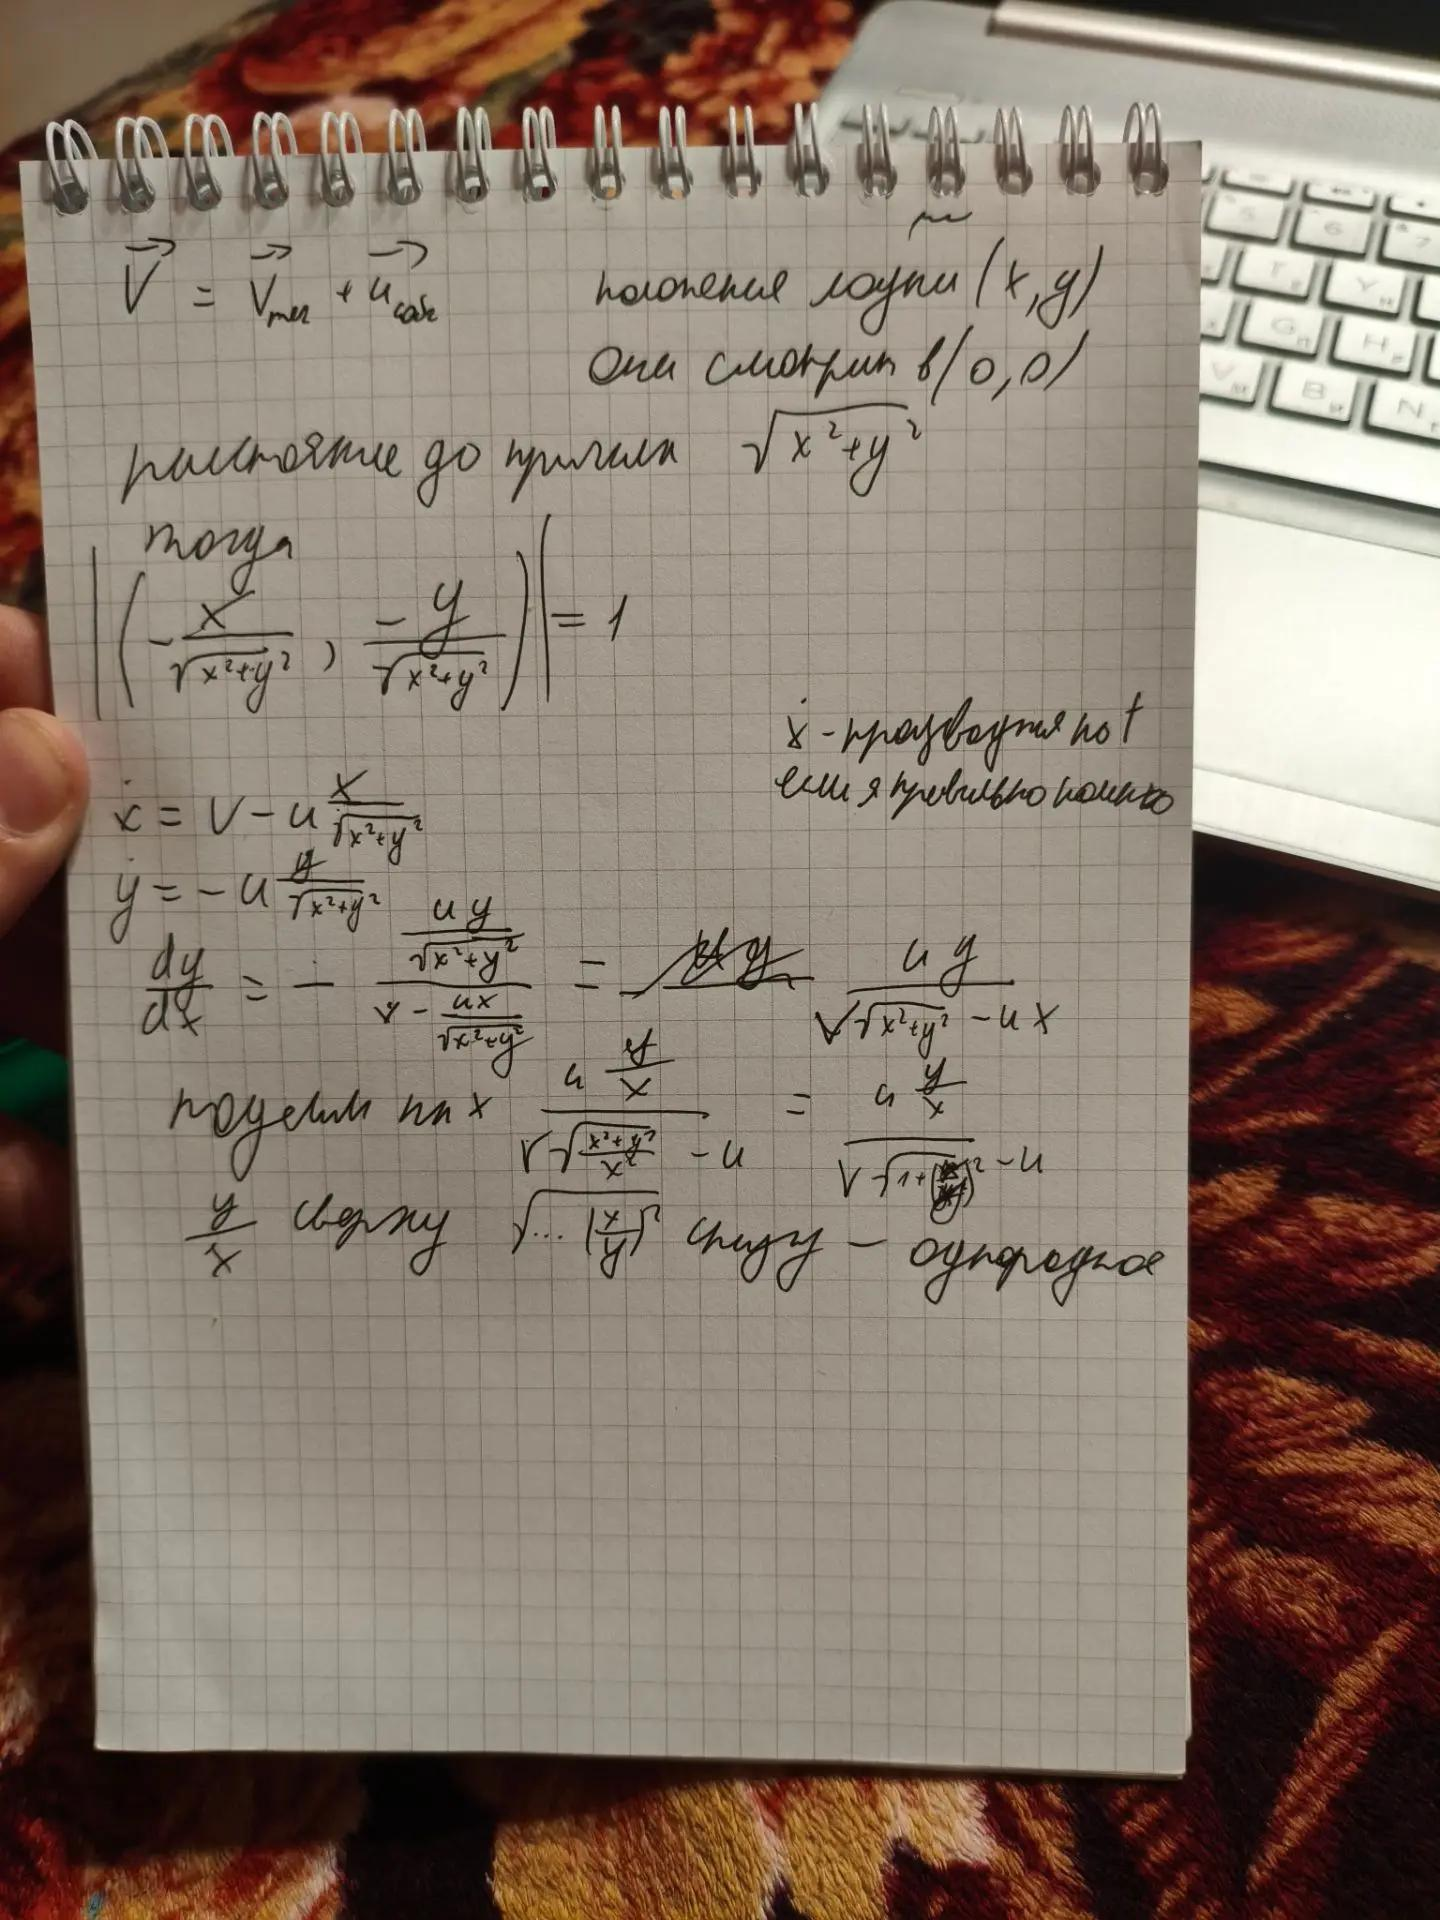

In [61]:
import sympy as sp

x = sp.Symbol('x')
y = sp.Function('y')(x)
u = sp.Symbol('u')
v = sp.Symbol('v')

ode = sp.Eq(y.diff(x), -y * u / (v * sp.sqrt(x**2 + y**2) - u*x))

sp.pprint(ode)

sol = sp.dsolve(ode, y)
sp.pprint(sol)

d                  -u⋅y(x)         
──(y(x)) = ────────────────────────
dx                     ____________
                      ╱  2    2    
           -u⋅x + v⋅╲╱  x  + y (x) 
                        ⎛ x  ⎞
                 u⋅asinh⎜────⎟
                        ⎝y(x)⎠
log(y(x)) = C₁ - ─────────────
                       v      


решение получилось но в неявном виде

log(y) = C1 - u * asinh(x/y)/ v
в задании указано
 DSolve может вернуть решение в неявном виде или через
   InverseFunction — это нормально для этого класса уравнений
поэтому норм

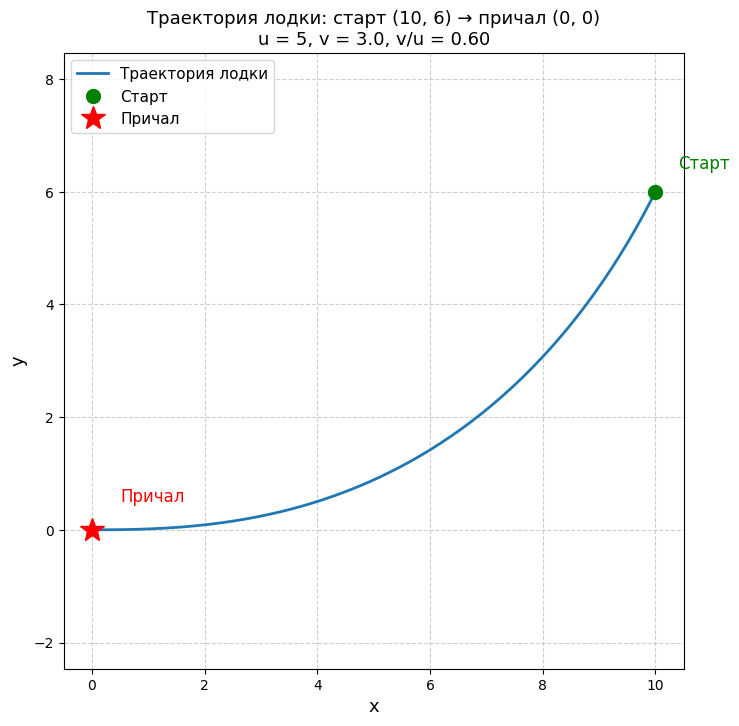

In [62]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

x0 = 10.0
y0 = 6.0

u_val = 5
v_val = 3.0

def f(t, state):
    x, y = state
    r = np.sqrt(x**2 + y**2)
    if r < 1e-9:
        return [0.0, 0.0]
    return [v_val - u_val * x / r, -u_val * y / r]

def prichal(t, state):
    x, y = state
    return np.sqrt(x**2 + y**2) - 1e-3

prichal.terminal = True
prichal.direction = -1

tmax = 500.0

sol = solve_ivp(
    f,
    (0.0, tmax),
    [x0, y0],
    events=prichal,
    max_step=0.05,
    rtol=1e-10,
    atol=1e-12,
)

x_arr = sol.y[0].copy()
y_arr = sol.y[1].copy()

if sol.t_events[0].size > 0:
    x_arr = np.append(x_arr, 0.0)
    y_arr = np.append(y_arr, 0.0)

#признаюсь честно дальше отрисовку графика написала нейронка я сам написал
#plt.plot(x_arr, y_arr)
#plt.xlabel("x")
#plt.ylabel("y")
#plt.grid(True)
#plt.show()
#я понимал что где но легенды и т.д. отдал нейросети на написание
fig, ax = plt.subplots(figsize=(8, 8))

ax.plot(x_arr, y_arr, color='tab:blue', linewidth=2, label='Траектория лодки')

ax.plot(x0, y0, marker='o', markersize=10, color='green',
        linestyle='None', label='Старт')
ax.annotate('Старт', xy=(x0, y0), xytext=(x0 + 0.4, y0 + 0.4),
            fontsize=12, color='green')

ax.plot(0, 0, marker='*', markersize=18, color='red',
        linestyle='None', label='Причал')
ax.annotate('Причал', xy=(0, 0), xytext=(0.5, 0.5),
            fontsize=12, color='red')

ax.set_xlabel('x', fontsize=13)
ax.set_ylabel('y', fontsize=13)
ax.set_title('Траектория лодки: старт (10, 6) → причал (0, 0)\n'
             f'u = {u_val}, v = {v_val}, v/u = {v_val/u_val:.2f}',
             fontsize=13)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper left', fontsize=11)
ax.axis('equal')

plt.show()

И тут я снова удивился, изначально я не заметил k и решал все с v u тут пришлось вводить k, но старое я не стал переделывать

0.3 причалила
0.6 причалила
0.9 причалила
0.95 причалила
0.99 причалила
1.0 снос
1.05 снос
1.1 снос


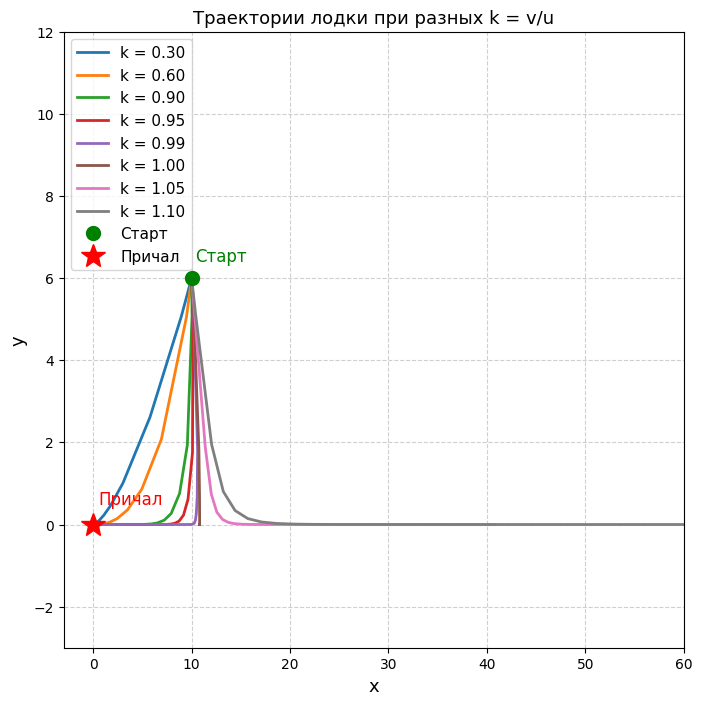

In [63]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

x0 = 10.0
y0 = 6.0

u_val = 1.0
k_val = 0.5

def f(t, state):
    x, yy = state
    r = np.sqrt(x**2 + yy**2)
    if r < 1e-9:
        return [0.0, 0.0]
    return [k_val * u_val - u_val * x / r, -u_val * yy / r]

def prichal(t, state):
    x, yy = state
    return np.sqrt(x**2 + yy**2) - 1e-2

prichal.terminal = True
prichal.direction = -1

ks = [0.3, 0.6, 0.9, 0.95, 0.99, 1.0, 1.05, 1.1]

fig, ax = plt.subplots(figsize=(8, 8))

for kv in ks:
    k_val = kv
    if kv < 1.0:
        tmax = 300.0 / (1.0 - kv) + 100.0
    else:
        tmax = 600.0

    sol = solve_ivp(f, (0.0, tmax), [x0, y0], events=prichal)

    x_arr = sol.y[0]
    y_arr = sol.y[1]

    if sol.t_events[0].size > 0:
        x_arr = np.append(x_arr, 0.0)
        y_arr = np.append(y_arr, 0.0)
        status = "причалила"
    else:
        status = "снос"

    print(kv, status)

    ax.plot(x_arr, y_arr, linewidth=2, label=f'k = {kv:.2f}')
#тут опираясь на прошлое решение нейронки для вывода сделал сам
ax.plot(x0, y0, marker='o', markersize=10, color='green',
        linestyle='None', label='Старт')
ax.annotate('Старт', xy=(x0, y0), xytext=(x0 + 0.4, y0 + 0.4),
            fontsize=12, color='green')

ax.plot(0, 0, marker='*', markersize=18, color='red',
        linestyle='None', label='Причал')
ax.annotate('Причал', xy=(0, 0), xytext=(0.5, 0.5),
            fontsize=12, color='red')

ax.set_xlabel('x', fontsize=13)
ax.set_ylabel('y', fontsize=13)
ax.set_title('Траектории лодки при разных k = v/u', fontsize=13)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper left', fontsize=11)
ax.set_xlim(-3, 60)
ax.set_ylim(-3, 12)

plt.show()